In [9]:
from train.train_lstm import train_lstm_pipeline
import json
import pandas as pd
from pytorch_lightning import Trainer
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, TQDMProgressBar
from pytorch_lightning.loggers import CSVLogger
from tqdm import tqdm

In [10]:
ALL_VIDEOS = [
    # ('session0', 'center'),
    # ('session0', 'left'),
    # ('session0', 'right'),
    ('session1', 'center'),
    ('session1', 'left'),
    ('session1', 'right'),
    ('session2', 'center'),
    ('session2', 'left'),
    ('session2', 'right'),
    ('session3', 'center'),
    ('session3', 'left'),
    ('session3', 'right'),
    ('session4', 'center'),
    ('session4', 'left'),
    ('session4', 'right'),
    ('session5', 'center'),
    ('session5', 'left'),
    ('session5', 'right'),
    ('session6', 'center'),
    ('session6', 'left'),
    ('session6', 'right'),
]

In [ ]:
def extract_features(car):
    speed = car.get('gt_data', {}).get('speed', None)
    features = []
    fdatas = car['fdata']
    for fdata in fdatas:
        [x1, y1], [x2, y2] = fdata['bbox']['pos']
        bbox_center = fdata['bbox']['center']
        bbox_width, bbox_height = fdata['bbox']['dims']
        bbox_area, bbox_aspect_ratio = fdata['bbox']['area'], fdata['bbox']['aspect_ratio'] # may change aspect_ratio for (width / height)
        [rx1, ry1], [rx2, ry2], [rx3, ry3], [rx4, ry4] = fdata['rotated_bbox']['pos']
        rbbox_center = fdata['rotated_bbox']['center']
        rbbox_width, rbbox_height = fdata['rotated_bbox']['dims']
        rbbox_area, rbbox_angle, rbbox_aspect_ratio = fdata['rotated_bbox']['area'], fdata['rotated_bbox']['angle'], fdata['rotated_bbox']['aspect_ratio']
        bottom_x, bottom_y = fdata['bottom']
        mask_area = fdata['mask_area']

        features.append([
            # x1, y1, x2, y2,
            # bbox_center[0], bbox_center[1],
            # bbox_width, bbox_height,
            bottom_x, bottom_y,
            bbox_aspect_ratio,
            # rx1, ry1, rx2, ry2, rx3, ry3, rx4, ry4,
            # rbbox_center[0], rbbox_center[1],
            # rbbox_width, rbbox_height,
            rbbox_angle,
            rbbox_aspect_ratio,
            mask_area,
        ])
    return {
        'features': features,
        'speed': speed
    }

In [12]:
data_list = []
for session, recording in ALL_VIDEOS:
    with open(f'../../results/{session}_{recording}/tracked_cars_data.json', 'r') as f:
        cars = json.load(f)['cars']
        valid_cars = list(filter(lambda car: car.get('gt_data', {}).get('speed', None) is not None, cars))
        data_list.extend([extract_features(car) for car in valid_cars])


In [13]:
input_size = len(data_list[0]['features'][0])

data_module, model, trainer, logger = train_lstm_pipeline(
    # Dataset
    data_list,

    # DataModule params
    batch_size=4,
    split_ratio=(0.8, 0.1, 0.1),
    num_workers=4,

    # LSTM params
    input_size=input_size,
    hidden_size=64,
    num_layers=2,
    output_size=1,
    learning_rate=1e-3,
    dropout=0.0,

    # Logger
    log_path='tracking_lstm_sc',

    # Trainer
    patience=7,
    epochs=200,
    log_every_n_steps=10,
)

trainer.test(model, datamodule=data_module)

INFO:pytorch_lightning.utilities.rank_zero:Trainer will use only 1 of 4 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=4)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3]
INFO:pytorch_lightning.callbacks.model_summary:
   | Name      | Type                       | Params | Mode 
------------------------------------------------------------------
0  | lstm      | LSTM                       | 54.8 K | train
1  | dropout   | Dropout                    | 0      | train
2  | fc        | Linear                     |

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (40 outputs left out)

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3]


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.9825776815414429     │
│         test_loss         │    4.8266448974609375     │
│         test_mae          │    1.3520796298980713     │
│         test_mse          │    4.8266448974609375     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 4.8266448974609375,
  'test_mse': 4.8266448974609375,
  'test_mae': 1.3520796298980713,
  'test_acc': 0.9825776815414429}]

In [14]:
predictions = trainer.predict(model, dataloaders=data_module.test_dataloader())
pred_df = pd.DataFrame(predictions, columns=["pred", "target"])

INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1,2,3]


Predicting: |          | 0/? [00:00<?, ?it/s]

In [15]:
df_pred = pd.DataFrame(
    [
        (
            pred[i].item(),
            real[i].item(),
            abs(pred[i].item() - real[i].item())
        )
        for (pred, real) in predictions
        for i in range(len(pred))
    ],
    columns=["Velocidad Predicha", "Velocidad Real", "Error km/h"]
)
df_pred.head(20)

,Velocidad Predicha,Velocidad Real,Error km/h
0,74.165894,74.696404,0.530510
1,108.007423,104.778000,3.229424
2,93.537529,92.397598,1.139931
3,83.258263,83.257202,0.001060
4,65.790382,65.901604,0.111221
5,104.336517,104.061600,0.274918
6,81.763878,82.047600,0.283722
7,84.600746,83.484001,1.116745
8,70.218498,68.094002,2.124496
9,86.315437,84.290398,2.025040


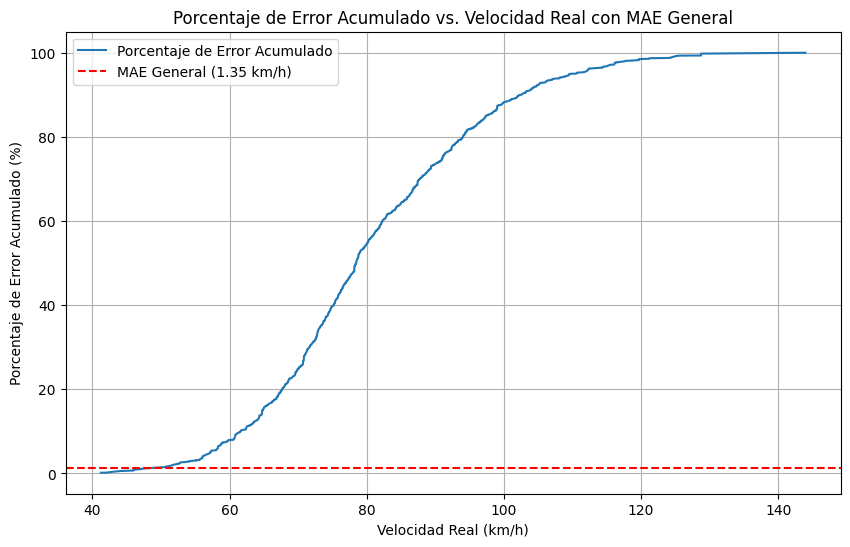

In [27]:
# 1. Gráfica de error acumulado porcentual vs. Velocidad Real con Error Absoluto Medio
df_sorted_speed = df_pred.sort_values('Velocidad Real').reset_index(drop=True)
df_sorted_speed['Error Absoluto'] = abs(df_sorted_speed['Error km/h'])

# Calcular el error acumulado y el porcentaje acumulado
df_sorted_speed['Error Acumulado'] = df_sorted_speed['Error Absoluto'].cumsum()
df_sorted_speed['Porcentaje Error Acumulado'] = (df_sorted_speed['Error Acumulado'] / df_sorted_speed['Error Absoluto'].sum()) * 100

# Calcular el Error Absoluto Medio (MAE) general
mae_general = df_sorted_speed['Error Absoluto'].mean()

plt.figure(figsize=(10, 6))
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Porcentaje Error Acumulado'], label='Porcentaje de Error Acumulado')

# Agregar línea horizontal para el MAE general
plt.axhline(y=mae_general, color='red', linestyle='--', label=f'MAE General ({mae_general:.2f} km/h)')

plt.title('Porcentaje de Error Acumulado vs. Velocidad Real con MAE General')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Porcentaje de Error Acumulado (%)')
plt.legend()
plt.grid(True)
plt.show()


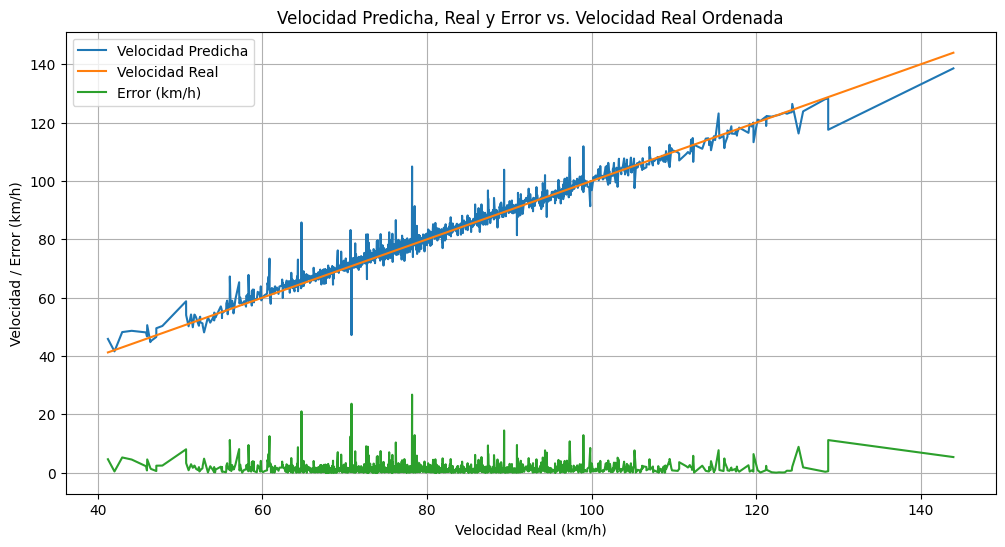

In [20]:
# 2. Gráfica de triple línea (Predicha, Real, Error) vs. Velocidad Real ordenada
df_sorted_speed = df_pred.sort_values('Velocidad Real').reset_index(drop=True)

plt.figure(figsize=(12, 6))
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Velocidad Predicha'], label='Velocidad Predicha')
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Velocidad Real'], label='Velocidad Real')
plt.plot(df_sorted_speed['Velocidad Real'], df_sorted_speed['Error km/h'], label='Error (km/h)')
plt.title('Velocidad Predicha, Real y Error vs. Velocidad Real Ordenada')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Velocidad / Error (km/h)')
plt.legend()
plt.grid(True)
plt.show()


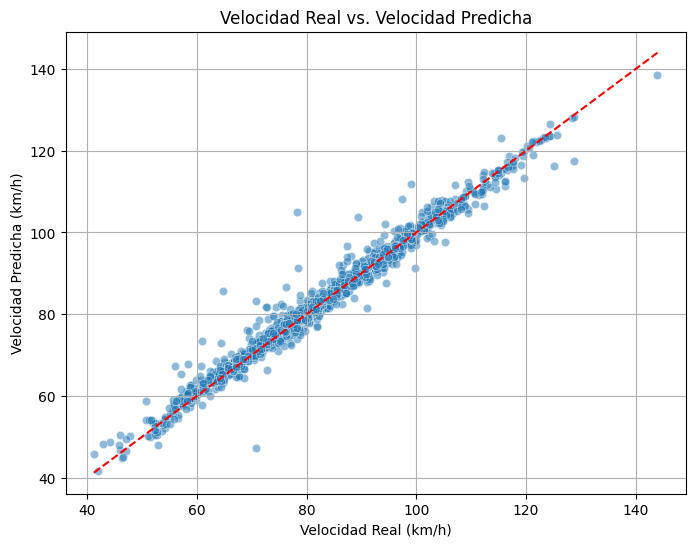

In [21]:
# 3. Gráfico de dispersión de Velocidad Real vs. Velocidad Predicha
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Velocidad Real', y='Velocidad Predicha', data=df_pred, alpha=0.5)
plt.plot([df_pred['Velocidad Real'].min(), df_pred['Velocidad Real'].max()],
         [df_pred['Velocidad Real'].min(), df_pred['Velocidad Real'].max()],
         color='red', linestyle='--')
plt.title('Velocidad Real vs. Velocidad Predicha')
plt.xlabel('Velocidad Real (km/h)')
plt.ylabel('Velocidad Predicha (km/h)')
plt.grid(True)
plt.show()


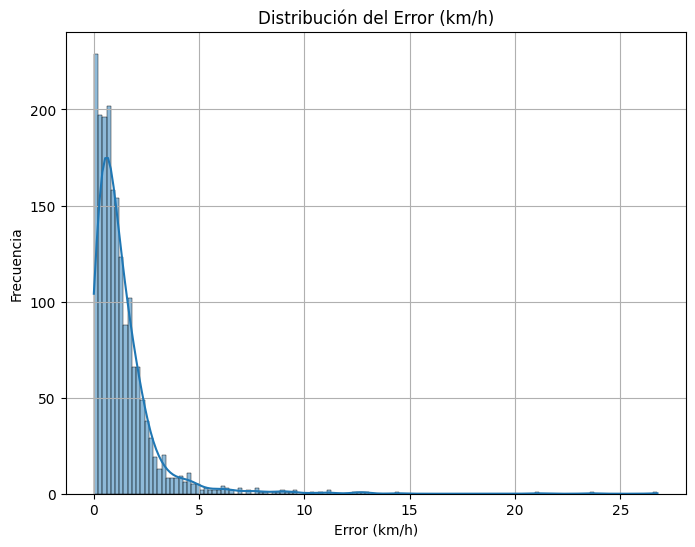

In [22]:
# 4. Histograma del Error
plt.figure(figsize=(8, 6))
sns.histplot(df_pred['Error km/h'], kde=True)
plt.title('Distribución del Error (km/h)')
plt.xlabel('Error (km/h)')
plt.ylabel('Frecuencia')
plt.grid(True)
plt.show()


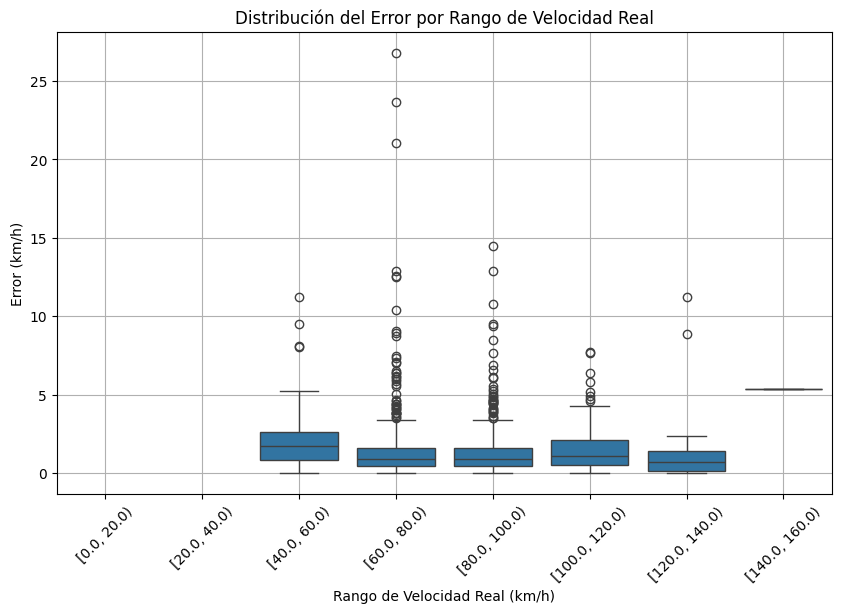

In [24]:
# 5. Gráfico de caja del Error por rangos de Velocidad Real
# Define los rangos de velocidad
bins = np.arange(0, df_pred['Velocidad Real'].max() + 20, 20)
df_pred['Rango Velocidad Real'] = pd.cut(df_pred['Velocidad Real'], bins=bins, right=False)

plt.figure(figsize=(10, 6))
sns.boxplot(x='Rango Velocidad Real', y='Error km/h', data=df_pred)
plt.title('Distribución del Error por Rango de Velocidad Real')
plt.xlabel('Rango de Velocidad Real (km/h)')
plt.ylabel('Error (km/h)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()


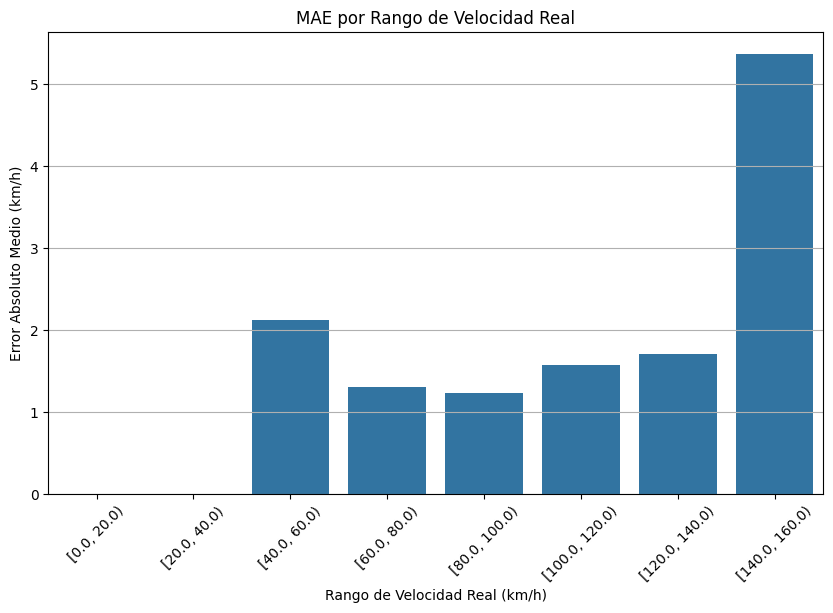

In [25]:
# 6. Gráfico de error absoluto medio (MAE) por rangos de Velocidad Real
mae_por_rango = df_pred.groupby('Rango Velocidad Real')['Error km/h'].mean().reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(x='Rango Velocidad Real', y='Error km/h', data=mae_por_rango)
plt.title('MAE por Rango de Velocidad Real')
plt.xlabel('Rango de Velocidad Real (km/h)')
plt.ylabel('Error Absoluto Medio (km/h)')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


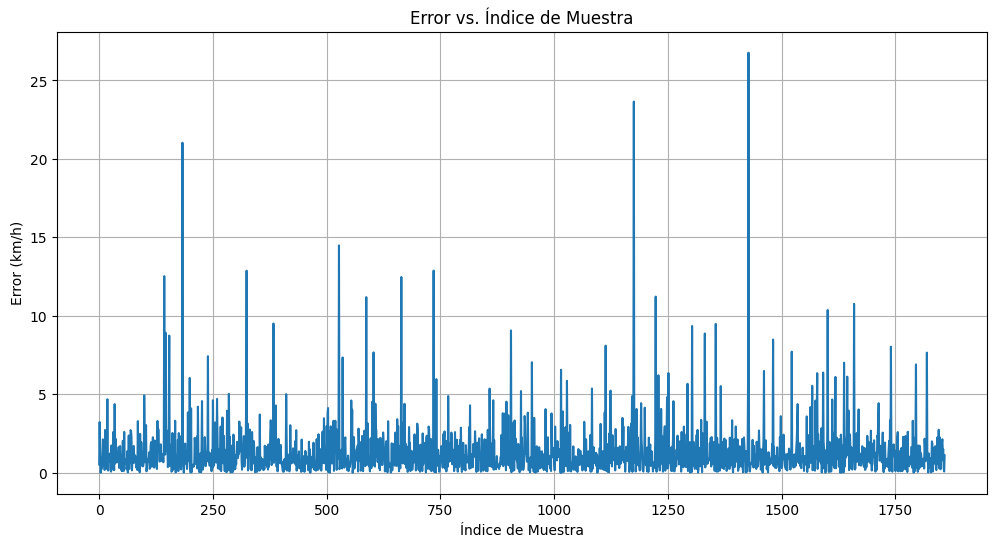

In [26]:
# 7. Gráfico de error vs. índice de muestra (asumiendo que el DataFrame tiene un orden)
plt.figure(figsize=(12, 6))
plt.plot(df_pred.index, df_pred['Error km/h'])
plt.title('Error vs. Índice de Muestra')
plt.xlabel('Índice de Muestra')
plt.ylabel('Error (km/h)')
plt.grid(True)
plt.show()


<Axes: title={'center': 'Precisión Relativa de Entrenamiento y Validación'}, xlabel='Epoch', ylabel='Accuracy'>

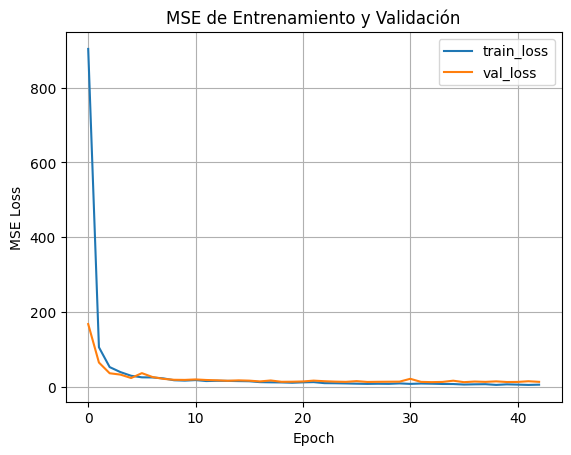

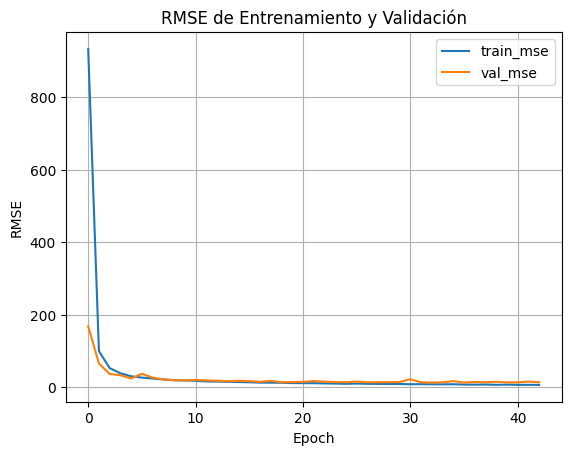

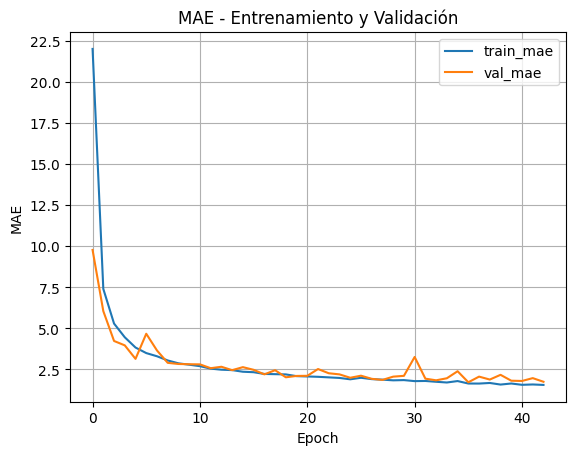

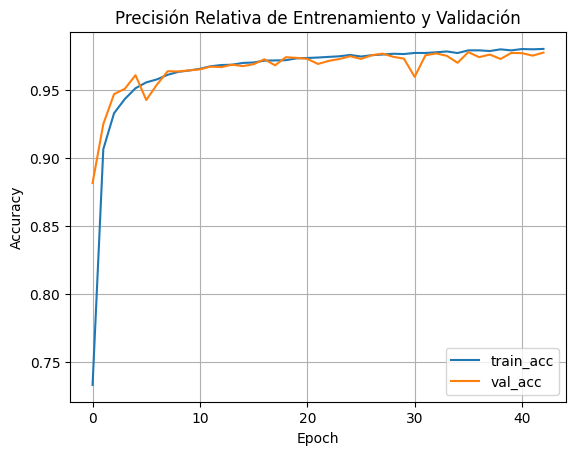

In [16]:
metrics = pd.read_csv(f"{trainer.logger.log_dir}/metrics.csv")

aggreg_metrics = []
agg_col = "epoch"
for i, dfg in metrics.groupby(agg_col):
    agg = dict(dfg.mean())
    agg[agg_col] = i
    aggreg_metrics.append(agg)

df_metrics = pd.DataFrame(aggreg_metrics)

df_metrics[["train_loss", "val_loss"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch",
    ylabel="MSE Loss", 
    # ylim=(0, 500),
    title="MSE de Entrenamiento y Validación", 
)

df_metrics[["train_mse", "val_mse"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="RMSE",
    title="RMSE de Entrenamiento y Validación",
)

df_metrics[["train_mae", "val_mae"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="MAE",
    title="MAE - Entrenamiento y Validación",
)

df_metrics[["train_acc", "val_acc"]].plot(
    grid=True, 
    legend=True, 
    xlabel="Epoch", 
    ylabel="Accuracy",
    title="Precisión Relativa de Entrenamiento y Validación",
)

